# Ejercicio 2 — Cuadrados mínimos

Estimar $x$ minimizando $\|Ax-b\|_2$.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from comun import cargar_datos

datos = cargar_datos()
lam, A, edades, b, b_ideal, x_real = (
    datos[k] for k in ("lam", "A", "edades", "b", "b_ideal", "x_real")
)

FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

e = b - b_ideal
eta = np.linalg.norm(e)
m, n = A.shape

print("Forma de A:", A.shape, "| m =", m, "| n =", n)
print("η = ||b - b_ideal||_2 =", eta)

Forma de A: (4300, 15) | m = 4300 | n = 15
η = ||b - b_ideal||_2 = 0.11465949557718051


## 1. Planteo

Como $A \in \mathbb{R}^{4300\times15}$ tiene muchas más filas que columnas, el sistema $Ax=b$ es **sobredeterminado** y, con ruido, no tiene solución exacta. Se busca entonces

$$x_{LS} = \arg\min_{x\in\mathbb{R}^{15}} \|Ax-b\|_2^2 .$$

Si $A$ tiene rango completo de columnas ($\operatorname{rg}A = 15$), el mínimo es único y cumple las **ecuaciones normales** $A^\top A\,x = A^\top b$. Geométricamente, $Ax_{LS}$ es la proyección ortogonal de $b$ sobre $\operatorname{Col}(A)$, y el residuo $r = b - Ax_{LS}$ es ortogonal a ese subespacio ($A^\top r = 0$).

No se imponen las restricciones físicas $x\ge0$ y $\mathbf 1^\top x = 1$: se resuelve el problema lineal sin restricciones y después se verifica si las cumple.

## 2. Resolución numérica

Se resuelve de tres maneras para comparar su estabilidad:

- **`np.linalg.lstsq`** (basado en la SVD, vía LAPACK).
- **QR reducida:** $A = QR$, con $Q\in\mathbb{R}^{4300\times15}$ de columnas ortonormales y $R$ triangular superior. Como $\|Ax-b\|_2^2 = \|Rx - Q^\top b\|_2^2 + \|(I-QQ^\top)b\|_2^2$, basta resolver $Rx = Q^\top b$ por sustitución hacia atrás.
- **Ecuaciones normales:** $A^\top A\,x = A^\top b$.

**Resultados.**

- $A$ tiene rango numérico 15 y $\kappa_2(A) \approx 6{,}1\times10^{3}$, en tanto que $\kappa_2(A^\top A) = \kappa_2(A)^2 \approx 3{,}7\times10^{7}$. Formar $A^\top A$ **eleva al cuadrado el condicionamiento**.
- QR coincide con `lstsq` a precisión de máquina (diferencia relativa $\sim10^{-12}$). Las ecuaciones normales pierden unos 3 dígitos más ($\sim10^{-9}$), consistente con $\kappa^2\varepsilon_{maq} \approx 3{,}7\times10^{7}\cdot2{,}2\times10^{-16} \approx 10^{-8}$.
- Acá esa pérdida no cambia nada en la práctica: el error que introduce el ruido de los datos es muchísimo mayor. Igual, QR o SVD son la opción correcta, y con un $A$ peor condicionado las ecuaciones normales sí fallarían.
- Se verifica $\|A^\top r\| \approx 4\times10^{-13}$: el residuo es ortogonal a las columnas de $A$, como predice la teoría.

In [2]:
x_ls, res, rank, sv = np.linalg.lstsq(A, b, rcond=None)
print("Rango numérico de A (lstsq):", rank)

# QR reducida: Q (4300 x 15) con columnas ortonormales, R (15 x 15) triangular superior
Q, R = np.linalg.qr(A)
x_qr = np.linalg.solve(R, Q.T @ b)

# Ecuaciones normales: (A^T A) x = A^T b
x_ne = np.linalg.solve(A.T @ A, A.T @ b)

print("cond(A) =", np.linalg.cond(A))
print("cond(A^T A) =", np.linalg.cond(A.T @ A))
print("cond(A)^2 =", np.linalg.cond(A) ** 2)
print("||x_QR - x_LS|| / ||x_LS|| =", np.linalg.norm(x_qr - x_ls) / np.linalg.norm(x_ls))
print("||x_NE - x_LS|| / ||x_LS|| =", np.linalg.norm(x_ne - x_ls) / np.linalg.norm(x_ls))
print("||A^T (b - A x_LS)|| =", np.linalg.norm(A.T @ (b - A @ x_ls)))

Rango numérico de A (lstsq): 15
cond(A) = 6065.839028354768
cond(A^T A) = 36794403.126733296
cond(A)^2 = 36794403.11791191
||x_QR - x_LS|| / ||x_LS|| = 9.705144992752545e-13
||x_NE - x_LS|| / ||x_LS|| = 1.474121155382794e-09
||A^T (b - A x_LS)|| = 4.1382788337775956e-13


## 3. Métricas

Se incluye $x_{real}$ como fila de referencia: es lo mejor que se podría lograr conociendo la respuesta.

- **El ajuste en el espacio de los datos es excelente:** $R^2 = 0{,}9999$, residuo relativo de $0{,}19\,\%$ y RMS del residuo $\approx 1{,}74\times10^{-3}$, igual al $\sigma$ del ruido.
- **El residuo de $x_{LS}$ es *menor* que el de $x_{real}$** ($\|r\| = 0{,}9976\,\eta$). No es un mejor ajuste: cuadrados mínimos, por construcción, minimiza el residuo y **absorbe parte del ruido** en la solución. La parte del ruido que cae en $\operatorname{Col}(A)$ ($Pe$, con $P$ el proyector) se interpreta como señal: $\|r\|^2 = \|(I-P)e\|^2 = \eta^2 - \|Pe\|^2$.
- **Reconstrucción contra el ideal:** $\|Ax_{LS} - b_{ideal}\|_2 \approx 0{,}0079 \ll \eta \approx 0{,}115$. El espectro reconstruido está ~15 veces más cerca de $b_{ideal}$ que el propio $b$, porque la proyección sobre un subespacio de dimensión 15 descarta casi todo el ruido. El valor esperado es $\|Pe\| \approx \sigma\sqrt{n} = 1{,}75\times10^{-3}\sqrt{15} \approx 0{,}0068$, consistente.
- **Pero en el espacio de los coeficientes el error es grande:** $\|x_{LS}-x_{real}\|/\|x_{real}\| \approx 17{,}6\,\%$, cuando el ruido relativo en $b$ es $0{,}19\,\%$. Es decir, el error relativo se amplifica unas **90 veces**, dentro de la cota $\kappa_2(A) \approx 6000$.
- **Restricciones físicas:** $\sum x_{LS} = 0{,}99999$ (se cumple casi exacto, por la fila normalizada en 5500 Å vista en el Ej. 1) y no hay componentes negativas con este $b$.

In [3]:
pd.set_option("display.float_format", "{:.6g}".format)


def metricas(x):
    r_x = A @ x - b
    nr = np.linalg.norm(r_x)
    nb = np.linalg.norm(b)
    return {
        "‖Ax − b‖₂": nr,
        "‖Ax − b‖₂ / η": nr / eta,
        "‖Ax − b‖ / ‖b‖": nr / nb,
        "RMS del residuo ‖Ax − b‖ / √m": nr / np.sqrt(m),
        "R² = 1 − ‖Ax − b‖² / ‖b − mean(b)‖²": 1 - nr ** 2 / np.linalg.norm(b - b.mean()) ** 2,
        "‖Ax − b_ideal‖₂": np.linalg.norm(A @ x - b_ideal),
        "‖x − x_real‖ / ‖x_real‖": np.linalg.norm(x - x_real) / np.linalg.norm(x_real),
        "max|x − x_real|": np.max(np.abs(x - x_real)),
        "Σ x": x.sum(),
        "componentes negativas": int(np.sum(x < 0)),
    }


tabla_metricas = pd.DataFrame({
    "x_LS": metricas(x_ls),
    "x_real (referencia)": metricas(x_real),
})

comp = pd.DataFrame({
    "edad [Gyr]": edades,
    "x_real": x_real,
    "x_LS": x_ls,
    "x_LS − x_real": x_ls - x_real,
    "error rel. (x_LS − x_real)/x_real": (x_ls - x_real) / x_real,
})

print("Por componente:")
print(comp.to_string(index=False, float_format=lambda v: f"{v:.6g}"))
print()
print("Métricas globales:")
tabla_metricas

Por componente:
 edad [Gyr]  x_real      x_LS  x_LS − x_real  error rel. (x_LS − x_real)/x_real
     0.0631    0.03 0.0316539     0.00165392                          0.0551308
     0.0891    0.04 0.0405785    0.000578527                          0.0144632
     0.1413    0.05  0.043345    -0.00665502                            -0.1331
     0.1995    0.06 0.0622342      0.0022342                          0.0372367
     0.2818    0.07 0.0706112    0.000611193                         0.00873132
     0.3981    0.08 0.0850761     0.00507607                          0.0634509
      0.631    0.09 0.0834078    -0.00659221                         -0.0732468
     0.8913     0.1  0.103303     0.00330264                          0.0330264
     1.2589     0.1  0.088648      -0.011352                           -0.11352
     1.9953     0.1  0.115798      0.0157984                           0.157984
     2.8184    0.08 0.0946049      0.0146049                           0.182561
     3.9811    0.06 0.03

,x_LS,x_real (referencia)
‖Ax − b‖₂,0.114389,0.114659
‖Ax − b‖₂ / η,0.997643,1
‖Ax − b‖ / ‖b‖,0.00187436,0.00187879
RMS del residuo ‖Ax − b‖ / √m,0.00174442,0.00174854
R² = 1 − ‖Ax − b‖² / ‖b − mean(b)‖²,0.999902,0.999902
‖Ax − b_ideal‖₂,0.00786813,1.09267e-08
‖x − x_real‖ / ‖x_real‖,0.17577,0
max|x − x_real|,0.0278394,0
Σ x,0.999986,1
componentes negativas,0,0


## 4. Coeficientes estimados vs. composición real

- En las **poblaciones jóvenes** (≤ 0,4 Gyr), $x_{LS}$ sigue de cerca a $x_{real}$: errores absolutos ≤ 0,007 y relativos de pocos por ciento (salvo 0,14 Gyr, con un 13 %).
- En las **poblaciones de edad intermedia y viejas** (≥ 1,3 Gyr) los errores crecen mucho: −46 % en 4 Gyr, +51 % en 8,9 Gyr, +18 % en 2,8 Gyr.
- Los errores tienden a **alternar de signo entre edades vecinas** (2 y 2,8 Gyr de más, 4 Gyr de menos; 8,9 Gyr de más, 5,6 y 12,6 Gyr de menos). Cuadrados mínimos **redistribuye peso entre columnas casi colineales**: subestimar una edad y sobreestimar la vecina cambia muy poco $Ax$. Esto conecta con el bloque de correlaciones ≈ 1 entre las SSP viejas del Ej. 1.
- La forma global de la distribución (unimodal, con el máximo en ~1–2 Gyr) se conserva, pero los valores individuales de las edades viejas no son confiables.

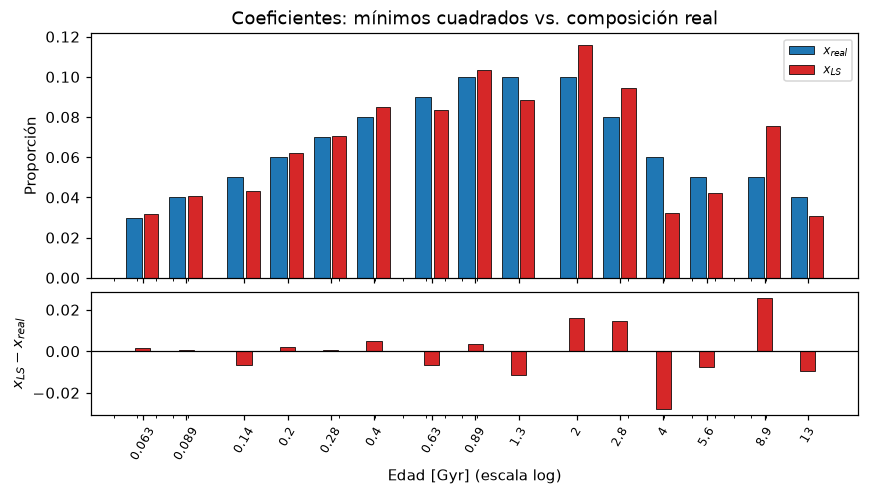

In [4]:
from matplotlib.ticker import NullFormatter

fig, (ax, ax_d) = plt.subplots(
    2, 1, figsize=(9, 4.5), sharex=True,
    gridspec_kw={"height_ratios": [2, 1], "hspace": 0.08},
)
for a in (ax, ax_d):
    a.set_xscale("log")

ancho = edades * 0.12
ax.bar(edades * 10 ** (-0.03), x_real, width=ancho, color="C0", edgecolor="k",
       linewidth=0.5, label="$x_{real}$")
ax.bar(edades * 10 ** (+0.03), x_ls, width=ancho, color="C3", edgecolor="k",
       linewidth=0.5, label="$x_{LS}$")
ax.set_ylabel("Proporción")
ax.set_title("Coeficientes: mínimos cuadrados vs. composición real")
ax.legend(fontsize=8)

ax_d.bar(edades, x_ls - x_real, width=ancho, color="C3", edgecolor="k", linewidth=0.5)
ax_d.axhline(0, color="k", linewidth=0.8)
ax_d.set_xlabel("Edad [Gyr] (escala log)")
ax_d.set_ylabel(r"$x_{LS} - x_{real}$")
ax_d.set_xticks(edades)
ax_d.set_xticklabels([f"{ed:.2g}" for ed in edades], rotation=60, fontsize=8)
ax_d.xaxis.set_minor_formatter(NullFormatter())

fig.savefig(FIG / "01_coeficientes.png")
plt.show()

## 5. Espectro reconstruido

- A la escala del espectro completo, y aun en el zoom de 3800–4400 Å donde están las features más marcadas, $Ax_{LS}$, $b$ y $Ax_{real}$ son **indistinguibles**.
- El residuo $r$ prácticamente coincide con el ruido verdadero: $\operatorname{corr}(r,e) = 0{,}998$ y $\operatorname{std}(r) = 1{,}744\times10^{-3}$ frente a $\operatorname{std}(e) = 1{,}748\times10^{-3}$. Es gaussiano, sin estructura en $\lambda$ y sin autocorrelación (rezago 1: 0,005).
- Es el diagnóstico de un **buen ajuste del modelo**: no queda señal sin explicar en el residuo. Pero esto **no dice nada** sobre si $x$ es correcto. Los mismos $b$ y residuo son compatibles con un $x$ que tiene un 18 % de error.

**Conclusión de esta sección:** evaluar la solución solo por el residuo o por la calidad visual del espectro reconstruido es engañoso cuando $A$ está mal condicionada.

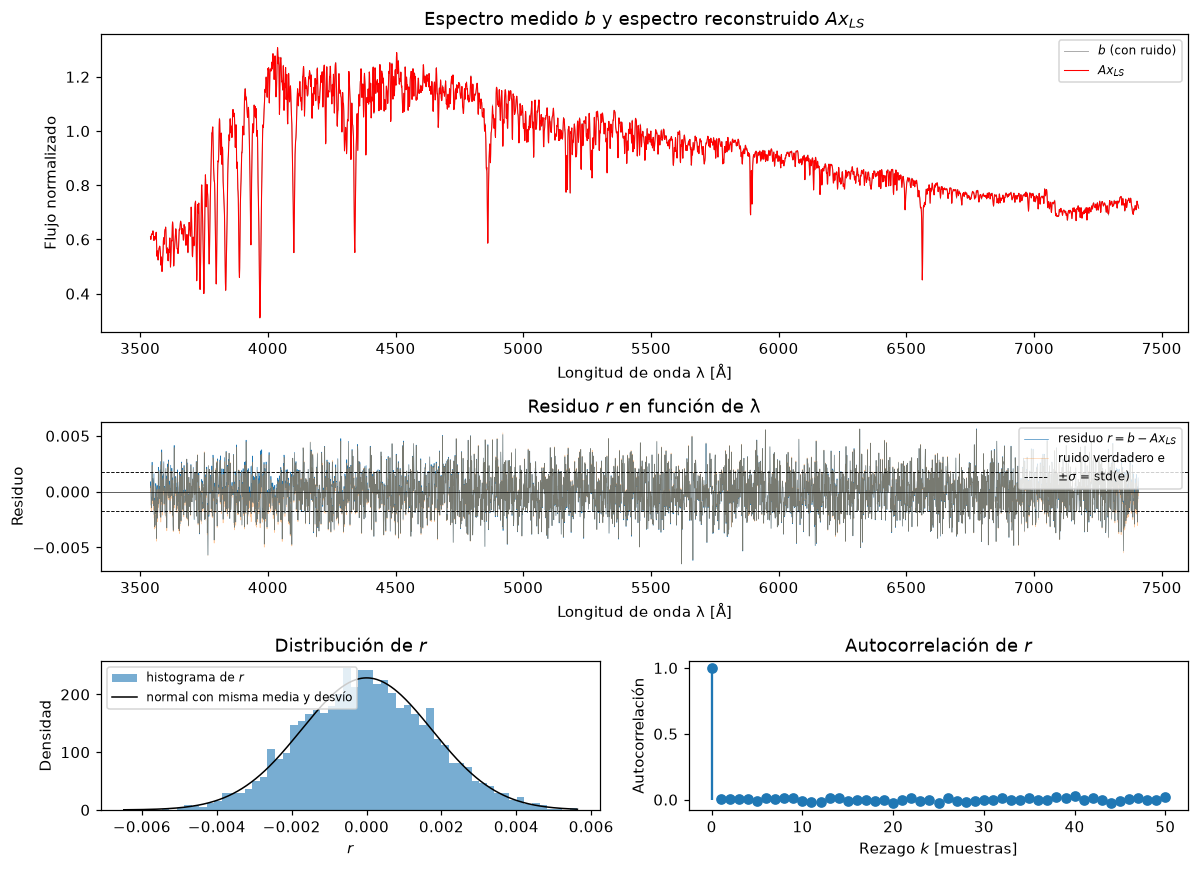

||r||_2 = 0.11438921469687811
||e||_2 = 0.11465949557718051
corr(r, e) = 0.9978314812723066
std(r) = 0.001744418685711899
std(e) = 0.0017482351083536072
autocorrelación de r de rezago 1 = 0.004602261532551654


In [5]:
r = b - A @ x_ls
ajuste = A @ x_ls
sigma_e = e.std()


def autocorrelacion(v, K=50):
    mu = v.mean()
    den = np.dot(v - mu, v - mu)
    ac = np.empty(K + 1)
    for k in range(K + 1):
        ac[k] = np.dot(v[:-k or None] - mu, v[k:] - mu) / den
    return ac


ac_r = autocorrelacion(r)
mr, sr = r.mean(), r.std()

fig, axd = plt.subplot_mosaic(
    [["s", "s"], ["r", "r"], ["h", "ac"]],
    figsize=(11, 8),
    height_ratios=[2, 1, 1],
)

ax = axd["s"]
ax.plot(lam, b, color="gray", alpha=0.7, linewidth=0.6, label="$b$ (con ruido)")
ax.plot(lam, ajuste, color="red", linewidth=0.7, label="$A x_{LS}$")
ax.set_xlabel("Longitud de onda λ [Å]")
ax.set_ylabel("Flujo normalizado")
ax.set_title("Espectro medido $b$ y espectro reconstruido $A x_{LS}$")
ax.legend(fontsize=8)

ax = axd["r"]
ax.plot(lam, r, linewidth=0.4, color="C0", label="residuo $r = b - A x_{LS}$")
ax.plot(lam, e, linewidth=0.4, color="C1", alpha=0.4, label="ruido verdadero e")
ax.axhline(sigma_e, color="k", linestyle="--", linewidth=0.6, label=r"$\pm\sigma$ = std(e)")
ax.axhline(-sigma_e, color="k", linestyle="--", linewidth=0.6)
ax.axhline(0, color="k", linewidth=0.4)
ax.set_xlabel("Longitud de onda λ [Å]")
ax.set_ylabel("Residuo")
ax.set_title("Residuo $r$ en función de λ")
ax.legend(fontsize=8, loc="upper right")

ax = axd["h"]
ax.hist(r, bins=60, density=True, alpha=0.6, label="histograma de $r$")
xs = np.linspace(r.min(), r.max(), 400)
pdf = np.exp(-0.5 * ((xs - mr) / sr) ** 2) / (sr * np.sqrt(2 * np.pi))
ax.plot(xs, pdf, color="k", linewidth=1, label="normal con misma media y desvío")
ax.set_xlabel("$r$")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de $r$")
ax.legend(fontsize=8)

ax = axd["ac"]
ax.stem(np.arange(len(ac_r)), ac_r, basefmt=" ")
ax.set_xlabel("Rezago $k$ [muestras]")
ax.set_ylabel("Autocorrelación")
ax.set_title("Autocorrelación de $r$")

fig.tight_layout()
fig.savefig(FIG / "02_espectro_residuo.png")
plt.show()

print("||r||_2 =", np.linalg.norm(r))
print("||e||_2 =", np.linalg.norm(e))
print("corr(r, e) =", np.corrcoef(r, e)[0, 1])
print("std(r) =", r.std())
print("std(e) =", e.std())
print("autocorrelación de r de rezago 1 =", ac_r[1])

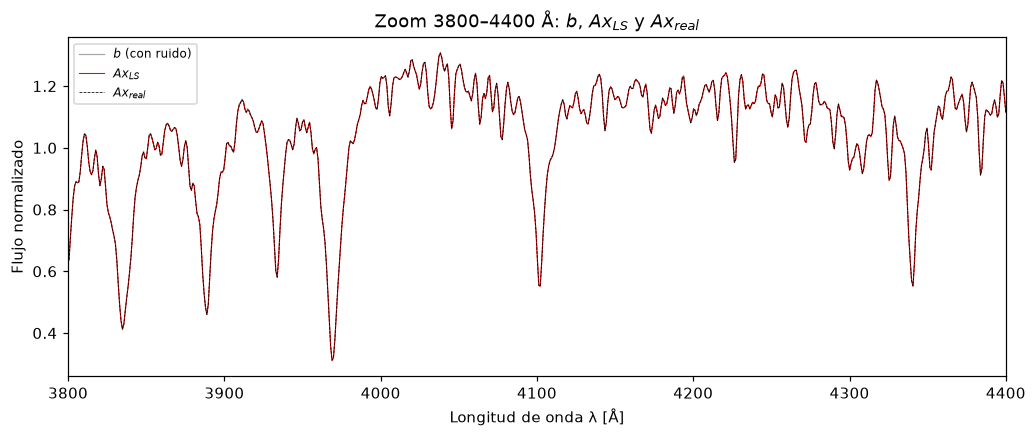

In [6]:
Ax_real = A @ x_real
mascara = (lam >= 3800) & (lam <= 4400)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(lam[mascara], b[mascara], color="gray", alpha=0.7, linewidth=0.8,
        label="$b$ (con ruido)")
ax.plot(lam[mascara], ajuste[mascara], color="red", linewidth=0.7, label="$A x_{LS}$")
ax.plot(lam[mascara], Ax_real[mascara], color="k", linewidth=0.5, linestyle="--",
        label="$A x_{real}$")
ax.set_xlim(3800, 4400)
ax.set_xlabel("Longitud de onda λ [Å]")
ax.set_ylabel("Flujo normalizado")
ax.set_title("Zoom 3800–4400 Å: $b$, $A x_{LS}$ y $A x_{real}$")
ax.legend(fontsize=8)

fig.savefig(FIG / "03_zoom_ajuste.png")
plt.show()

## 6. Sensibilidad al ruido

**(a) Sin ruido.** Con $b_{ideal}$, cuadrados mínimos recupera $x_{real}$ con un error relativo de $2\times10^{-8}$, del orden del redondeo de los CSV amplificado por $\kappa(A)$. El método no tiene sesgo: **todo el error viene del ruido**.

**(b) Con ruido: simulación Monte Carlo.** Se generaron 500 espectros $b_k = b_{ideal} + e_k$, con $e_k \sim \mathcal N(0,\sigma^2 I)$ y el mismo $\sigma$ del ruido dado, y se resolvió cuadrados mínimos en cada uno. Como $x_{LS} - x_{real} = A^{+}e$, la teoría predice $\operatorname{Cov}(x_{LS}) = \sigma^2 (A^\top A)^{-1} = \sigma^2 V\Sigma^{-2}V^\top$: las direcciones $v_i$ con $\sigma_i$ chico son las que más se amplifican.

- **Error relativo en $x$:** media del 22 % y desvío del 8 %. El 17,6 % obtenido con el $b$ dado cae en el **percentil 30**: no fue un caso de mala suerte, es lo típico.
- **Positividad:** en el **10 %** de las realizaciones aparece al menos una proporción **negativa**, que no tiene sentido físico.
- **Dispersión por componente:** el coeficiente de variación $\operatorname{std}/x_{real}$ es de 9–14 % entre 0,14 y 2 Gyr, pero sube al **31–59 %** entre 2,8 y 8,9 Gyr. Coincide con el bloque de SSP viejas casi colineales del Ej. 1.
- **Correlación entre estimaciones:** las estimaciones de edades vecinas están casi siempre **anticorrelacionadas**. En el par 0,063–0,089 Gyr (columnas con correlación ≈ 1,00 en el Ej. 1) llega a $-0{,}91$: el ruido hace que el método "pase" peso de una a la otra manteniendo casi constante su suma, que es lo que el espectro sí determina.

(a) ||x_id - x_real|| / ||x_real|| (LS sobre b_ideal) = 1.945939260927306e-08


Error relativo en x sobre las realizaciones: media = 0.22472138008037415 | desvío = 0.08281537968738704
Fracción de realizaciones con al menos una componente negativa = 0.1
Desvío por componente de x_k: [0.006  0.0081 0.0069 0.0063 0.0066 0.01   0.0118 0.0137 0.0114 0.0131
 0.0252 0.0352 0.028  0.0227 0.0118]
Coeficiente de variación por componente (desvío / x_real): [0.2  0.2  0.14 0.11 0.09 0.13 0.13 0.14 0.11 0.13 0.31 0.59 0.56 0.45
 0.3 ]
Error relativo de x_LS con el b dado = 0.17577017387021368
Percentil del error de x_LS con el b dado dentro de la distribución MC: 30.0
||r_k|| en MC: media = 0.11441469910881719 | ||e|| = 0.11465949557718051


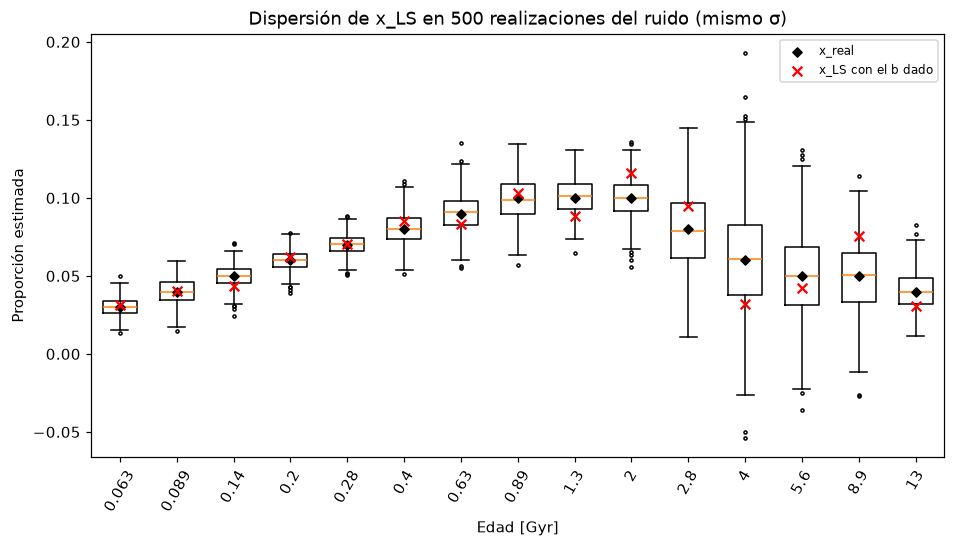

Par adyacente con correlación más negativa entre estimaciones: edades 0.063 y 0.089 Gyr
corr(x_i, x_j) = -0.9117879458110422
Correlaciones de pares adyacentes (i, i+1): [-0.91, -0.28, -0.7, 0.15, -0.63, -0.66, -0.79, -0.74, -0.25, -0.68, -0.6, -0.67, -0.28, -0.82]


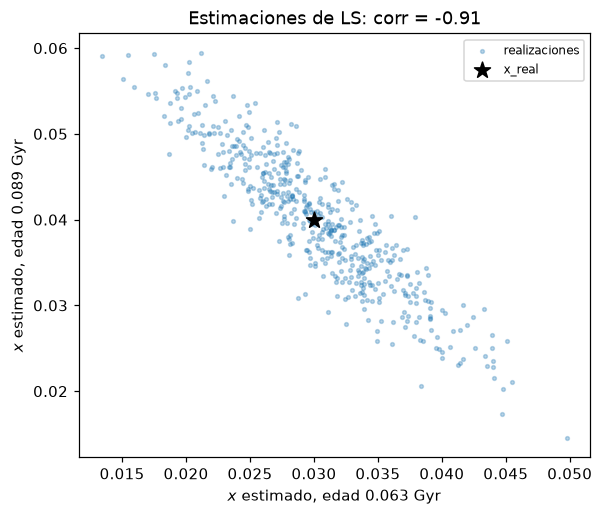

In [7]:
# (a) LS sobre el espectro sin ruido
x_id = np.linalg.lstsq(A, b_ideal, rcond=None)[0]
print("(a) ||x_id - x_real|| / ||x_real|| (LS sobre b_ideal) =",
      np.linalg.norm(x_id - x_real) / np.linalg.norm(x_real))

# (b) Monte Carlo: nuevas realizaciones del ruido con el mismo sigma
rng = np.random.default_rng(0)
sigma = e.std()
N = 500
X = np.empty((N, n))
normas_res = np.empty(N)
for k in range(N):
    bk = b_ideal + rng.normal(0, sigma, m)
    X[k] = np.linalg.lstsq(A, bk, rcond=None)[0]
    normas_res[k] = np.linalg.norm(bk - A @ X[k])

err_rel_mc = np.linalg.norm(X - x_real, axis=1) / np.linalg.norm(x_real)
err_rel_b = np.linalg.norm(x_ls - x_real) / np.linalg.norm(x_real)

print("Error relativo en x sobre las realizaciones: media =", err_rel_mc.mean(),
      "| desvío =", err_rel_mc.std())
print("Fracción de realizaciones con al menos una componente negativa =",
      np.mean((X < 0).any(axis=1)))
print("Desvío por componente de x_k:", np.round(X.std(axis=0), 4))
print("Coeficiente de variación por componente (desvío / x_real):",
      np.round(X.std(axis=0) / x_real, 2))
print("Error relativo de x_LS con el b dado =", err_rel_b)
print("Percentil del error de x_LS con el b dado dentro de la distribución MC:",
      100 * np.mean(err_rel_mc <= err_rel_b))
print("||r_k|| en MC: media =", normas_res.mean(), "| ||e|| =", np.linalg.norm(e))

# (c) Boxplot de las estimaciones por componente
etiquetas_edad = [f"{ed:.2g}" for ed in edades]
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(X, positions=np.arange(n), widths=0.6, flierprops={"markersize": 2})
ax.scatter(np.arange(n), x_real, color="k", marker="D", s=18, zorder=3, label="x_real")
ax.scatter(np.arange(n), x_ls, color="red", marker="x", s=40, zorder=4,
           label="x_LS con el b dado")
ax.set_xticks(np.arange(n))
ax.set_xticklabels(etiquetas_edad, rotation=60)
ax.set_ylabel("Proporción estimada")
ax.set_xlabel("Edad [Gyr]")
ax.set_title(f"Dispersión de x_LS en {N} realizaciones del ruido (mismo σ)")
ax.legend(fontsize=8)
fig.savefig(FIG / "04_montecarlo.png")
plt.show()

# (d) Correlación entre estimaciones de componentes adyacentes
Cx = np.corrcoef(X.T)
i_par = min(range(n - 1), key=lambda i: Cx[i, i + 1])
j_par = i_par + 1
print("Par adyacente con correlación más negativa entre estimaciones: edades",
      etiquetas_edad[i_par], "y", etiquetas_edad[j_par], "Gyr")
print("corr(x_i, x_j) =", Cx[i_par, j_par])
print("Correlaciones de pares adyacentes (i, i+1):",
      [round(float(Cx[i, i + 1]), 2) for i in range(n - 1)])

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X[:, i_par], X[:, j_par], s=6, alpha=0.3, label="realizaciones")
ax.scatter(x_real[i_par], x_real[j_par], color="k", marker="*", s=120, zorder=3,
           label="x_real")
ax.set_xlabel(f"$x$ estimado, edad {etiquetas_edad[i_par]} Gyr")
ax.set_ylabel(f"$x$ estimado, edad {etiquetas_edad[j_par]} Gyr")
ax.set_title(f"Estimaciones de LS: corr = {Cx[i_par, j_par]:.2f}")
ax.legend(fontsize=8)
fig.savefig(FIG / "05_correlacion_estimaciones.png")
plt.show()

## Conclusiones del ejercicio 2

1. El problema de cuadrados mínimos tiene solución única ($\operatorname{rg}A = 15$). Se resolvió en forma estable con QR o SVD. Las ecuaciones normales funcionan, pero pierden dígitos porque $\kappa(A^\top A) = \kappa(A)^2 \approx 3{,}7\times10^7$.
2. **En el espacio de los datos el ajuste es casi perfecto:** residuo ≈ $\eta$, $R^2 = 0{,}9999$, residuo indistinguible del ruido, y espectro reconstruido incluso más cercano a $b_{ideal}$ que el propio $b$.
3. **En el espacio de los coeficientes el error es del ~18 %** (típicamente 22 % ± 8 %). Un ruido del 0,19 % se amplifica ~100 veces por el mal condicionamiento de $A$ ($\kappa \approx 6\times10^3$), con errores concentrados en las edades viejas y de signo alternado entre edades vecinas. En un 10 % de los casos aparecen proporciones negativas.
4. **Un residuo chico no garantiza un $x$ correcto.** Cuadrados mínimos ajusta también parte del ruido; por eso su residuo es *menor* que el de la solución verdadera. Esto motiva analizar la estructura de $A$ con la SVD (Ej. 3) y regularizar (Ej. 4).